# **1. 이안류 CCTV 데이터셋**

​AI Hub의 '이안류 CCTV 데이터'는 우리나라 주요 해수욕장(해운대, 송정, 대천, 중문, 낙산)에서 이안류 발생 여부와 위치를 모니터링하기 위해 구축된 인공지능 학습용 데이터셋이다. 해수욕장 주변에 설치된 CCTV 영상을 이미지로 변환하여, 이안류 발생 여부와 위치를 가시화하는 모델 개발에 활용할 수 있다. 이 데이터셋은 이안류 탐지 및 예측 시스템 개발에 필수적인 자료를 제공하며, 해수욕객의 안전을 위한 응용 서비스 구성에 활용될 수 있다. ​이안류는 해안에서 먼 바다로 빠르게 이동하는 폭이 좁은 바닷물의 흐름으로, 기상 상태가 양호한 경우에도 나타나며, 얕은 곳에 있던 해수욕객을 순식간에 수심이 깊은 먼 바다로 이동시켜 인명사고를 유발할 수 있다. 따라서 이러한 데이터셋은 해수욕장 안전 관리 및 이안류 예측 모델 개발에 중요한 역할을 한다.

In [1]:
import json
import random
import shutil
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
from ultralytics import YOLO

# 실행 환경과 Ultralytics 설치 상태를 간단히 확인합니다.
import ultralytics
ultralytics.checks()

Ultralytics 8.4.135  Python-3.12.9 torch-2.13.0+cpu CPU (Intel Core Ultra 5 226V)
Setup complete  (8 CPUs, 15.6 GB RAM, 301.0/449.7 GB disk)


In [2]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [3]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
BASE_DIR = Path("./data").resolve()
ZIP_PATH = BASE_DIR / "ripcurrent.zip"
SAMPLE_DIR = BASE_DIR / "Sample"

SOURCE_IMAGE_DIR = SAMPLE_DIR / "01.원천데이터"
SOURCE_LABEL_DIR = SAMPLE_DIR / "02.라벨링데이터"

PROJECT_DIR = BASE_DIR / "ripcurrent"

TRAIN_DIR = PROJECT_DIR / "train"
VAL_DIR = PROJECT_DIR / "valid"
TEST_DIR = PROJECT_DIR / "test"

DATA_YAML = PROJECT_DIR / "ripcurrent.yaml"

In [5]:
MODEL_NAME = "model/yolo11s.pt"  # model 폴더 안에 저장/로드 (없으면 자동 다운로드하면서 폴더도 같이 생성됨)
IMAGE_SIZE = 640
EPOCHS = 50
PATIENCE = 10

BATCH_SIZE = 8
WORKERS = 0

TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1

CLASS_NAMES = {0: "rip_current"}

print('현재 작업 폴더: ', Path.cwd())
print('데이터 폴더: ', BASE_DIR)
print('프로젝트 폴더: ', PROJECT_DIR)
print('모델: ', MODEL_NAME)
print('device: ', DEVICE)
print('batch: ', BATCH_SIZE)

현재 작업 폴더:  c:\MCP\agentlog\mcp04_multimodal
데이터 폴더:  C:\MCP\agentlog\mcp04_multimodal\data
프로젝트 폴더:  C:\MCP\agentlog\mcp04_multimodal\data\ripcurrent
모델:  yolo11s.pt
device:  cpu
batch:  8


In [6]:
if SOURCE_IMAGE_DIR.exists() and SOURCE_LABEL_DIR.exists():
    print('이미 압축 해제된 데이터가 있습니다.')
else:
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f'압축 파일을 찾을 수 없습니다: {ZIP_PATH}\n'
                                "BASE_DIR 또는 ZIP_PATH를 확인하세요.")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(BASE_DIR)
    print('압출 해제 완료')

이미 압축 해제된 데이터가 있습니다.


# **2. JSON Bounding Box to YOLO Bounding Box**

원본 JSON의 drawing에는 객체를 둘러싼 사각형의 점 좌표가 들어있으므로 YOLO의 일반적인 객체 탐지 라벨 형식으로 변화시켜줘야 한다.
- class_id x_center y_center width height(네 개의 좌표를 모두 0 ~ 1 사이로 정규화)
- x_min: 객체의 가장 왼쪽 x
- y_min: 객체의 가장 위쪽 y
- x_max: 객체의 가장 오른쪽 x
- y_max: 객체의 가장 아래쪽 y

In [7]:
def json_to_yolo(points, image_width, image_height):
    """
    points: list [[x1, y1], [x2, y2], ... ] 사각형 점 좌표
    image_width: int 원본 이미지 너비
    image_height: int 원본 이미지 높이
    """
    if not points or len(points) < 2:
        return None

    xs = [float(point[0]) for point in points]
    ys = [float(point[1]) for point in points]

    # 네 점 중 가장 왼쪽/오른쪽/위/아래 좌표를 구함
    x_min = max(0.0, min(xs))
    y_min = max(0.0, min(ys))
    x_max = min(float(image_width), max(xs))
    y_max = min(float(image_height), max(ys))

    box_width = x_max - x_min
    box_height = y_max - y_min

    # 너비나 높이가 0 이하이면 정상적인 사각형이 아님
    if box_width <= 0 or box_height <= 0:
        return None

    # 픽셀 좌표 > YOLO 정규화 좌표
    x_center = ((x_min + x_max) / 2.0) / image_width
    y_center = ((y_min + y_max) / 2.0) / image_height
    width = box_width / image_width
    height = box_height / image_height

    return x_center, y_center, width, height

### JSON 파일을 읽어 YOLO 라벨로 변환하는 함수 만들기
함수 하나가 너무 많은 일을 담당하면 코드 수정과 테스트가 어려워진다.
1. JSON 파일 읽기
2. 이미지 해상도 확인
3. Bounding Box 변환
4. YOLO 한 줄 문자열 생성
5. 객체가 없다면 빈 리스트 반환
> 객체가 없는 경우도 오류가 아니다.
> 정상적인 background 이미지이다.

In [8]:
def make_yolo_labels(json_path):
    with json_path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    resolution = data['image_info']['resolution']
    image_width, image_height = map(int, resolution.split(","))
    drawings = data.get("annotations", {}).get("drawing") or [] # get(dict, default): 키가 없어도 KeyError 없이 default를 반환
    labels = []

    for points in drawings:
        yolo_box = json_to_yolo(points=points, image_width=image_width, image_height=image_height)
        if yolo_box is None:
            continue

        class_id = 0
        values = " ".join(f"{value:.6f}" for value in yolo_box)
        labels.append(f"{class_id} {values}")

    return sorted(set(labels)) # 중복값 제거

### JSON과 실제 이미지 연결하기

In [9]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", '.png', '.bmp', '.webp')

def find_source_image(json_path):
    stem = json_path.stem # 파일 이름만 가져올 수 있음
    for ext in IMAGE_EXTENSIONS:
        candidate = SOURCE_IMAGE_DIR / f'{stem}{ext}'
        if candidate.exists():
            return candidate
    return None

# **3. YOLO 데이터셋 만들기**

원본 이미지와 JSON label을 연결한 뒤 train/valid/test 폴더로 나눈다. 
```
같은 원본 영상에서 나온 프레임이 train과 test에 동시에 들어가면 성능이 실제보다 높게 보일 수 있으므로, 파일명 앞부분을 그룹으로 사용해 가능한 같은 영상 계열이 한 세트에만 들어가도록 분리한다.
```

In [10]:
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    (split_dir / "images").mkdir(parents=True, exist_ok=True)
    (split_dir / "labels").mkdir(parents=True, exist_ok=True)

# glob
json_files = sorted(SOURCE_LABEL_DIR.rglob("*.json"))
print('JSON 파일 수:', len(json_files))

JSON 파일 수: 360


In [ ]:
samples = []

for json_path in tqdm(json_files, desc="이미지-라벨 연결"): # 진행사항을 시각적으로 보여줌 
    candidates = []
    # extend(): 리스트에 여러 개의 요소를 추가할 수 있음
    # .rglob(), .glob(): 지정된 패턴에 맞는 파일을 검색하는 제너레이터, rglob()은 하위 디렉토리까지 검색
    for ext in IMAGE_EXTENSIONS:
        candidates.extend(SOURCE_IMAGE_DIR.rglob(f'{json_path.stem}{ext}')) # extend(): 리스트에 여러 개의 요소를 추가할 수 있음
    if not candidates:
        continue
    image_path = candidates[0] 
    yolo_labels = make_yolo_labels(json_path)
    samples.append({
        "image_path": image_path,
        "json_path": json_path,
        "labels": yolo_labels
    })

print("연결된 샘플 수:", len(samples))
print("객체가 있는 이미지:", sum(bool(s['labels']) for s in samples))
print("배경 이미지:", sum(not s['labels'] for s in samples))

이미지-라벨 연결: 100%|██████████| 360/360 [00:02<00:00, 149.63it/s]

연결된 샘플 수: 360
객체가 있는 이미지: 240
배경 이미지: 120


### 데이터수에 따른 YOLO 성능
- 전체 이미지: 360장
- 이안류 객체가 있는 이미지: 240장
- 배경 이미지: 120장
> YOLO는 단순히 이미지를 외우는 것이 아니라, 여러 이미지에서 반복적으로 나타나는 시각적 특징을 학습하여 새로운 이미지에서 객체를 찾아야 한다.
> 단순히 파일 갯수가 아니라 서로 다른 상황을 얼마나 다양하게 포함하고 있는가가 중요하다.

1. 360장이 곧 360개의 서로 다른 학습 경험을 의미하지 않음
    - CCTV 데이터는 연속된 시간의 프레임이 많이 포함될 수 있다.
    - 파일명이 몇 초 차이로 연속되어 있다면 서로 다른 파일이라도 실제 장면은 거의 동일할 수 있다.
    - 모델 입장에서는 비슷한 장면을 여러 번 반복해서 보는 효과가 커진다.
    - 다양성의 문제
2. 이안류는 일반 객체보다 시각적으로 경계가 모호하다.
    - 사람, 자동차, 동물처럼 외곽선이 비교적 명확한 객체와 달리 이안류는 복합적인 시각 정보를 통해 판단해야 한다.
    - 촬영 위치와 카메라 각도
    - 해안에서 바다 쪽으로 이어지는 흐름
    - 해수면 상태
    - 날씨와 시간대
> 작은 데이터셋에서 특정 해변, 특정 시간대, 특정 파도 모양만 반복되면 모델이 이안류 자체의 일반적인 특징보다 해당 CCTV 화면의 배경이나 위치를 외울 가능성이 높다.
3. 배경 이미지 120장은 불필요한 데이터가 아니다.
    - 객체가 없는 이미지는 YOLO에서 중요한 음성 샘필(Negativ sample)이다.
    - 해변이나 파도가 보인다고 해서 항상 이안류가 있는 것은 아니다.
    - 배경 이미지도 특정 장면만 반복되는 것이 아니라, 다양한 해변 상태를 포함하는 것이 좋다.
4. 데이터 부족의 대표적인 증상
    - 실제 이안류를 잘 찾지 못한다. >> Recall 감소
    - 육지, 파도 등을 이안류라고 잘못 탐지한다. >> Precision 감소
    - 예측 confidence가 전반적으로 낮다.
    - Validation 성능이 불안정하게 오르내린다.
    - 새로운 CCTV 장면에서 성능이 크게 떨어진다.
    - mAP50에 비해 mAP50-95가 매우 낮다.

In [19]:
# DC_MUDCH_20190705_133730.jpg > DC_MUDCH_20190705
# 파일명에서 마지막 시간/프레임 부분을 제외한 앞부분을 그룹으로 사용
def make_group_key(path):
    parts = path.stem.split("_") # 파일 이름을 '_'로 나눈 리스트 생성
    if len(parts) >= 2:
        return "_".join(parts[:-1]) # 시간만 제외해서 그룹 키 생성
    return path.stem

groups = np.array([make_group_key(s['image_path']) for s in samples])
indices = np.arange(len(samples))

splitter1 = GroupShuffleSplit( # group으로 묶어서 나눠줌
    n_splits=1,
    train_size=TRAIN_RATIO,
    random_state=SEED
)

train_idx, temp_idx = next( # 80% train, 20% temp (val+test) split
    splitter1.split(indices, groups=groups)
)

temp_groups = groups[temp_idx]
val_ratio = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

splitter2 = GroupShuffleSplit(
    n_splits=1,
    train_size=val_ratio,
    random_state=SEED
)

val_idx, test_idx = next(
    splitter2.split(temp_idx, groups=temp_groups)
)

val_idx = temp_idx[val_idx]
test_idx = temp_idx[test_idx]

split_indices = {
    "train": train_idx,
    "valid": val_idx,
    "test": test_idx
}
print(split_indices)

{'train': array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,  57,  58,  59,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153,
       154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215,
       216, 217, 218, 219, 220, 221, 22

In [13]:
for name, idx in split_indices.items():
    positive = sum(bool(samples[i]['labels']) for i in idx)
    negative = len(idx) - positive
    print(f'{name:5s}: {len(idx):4d}장 | '
          f'이안류 있음 {positive:4d} | 배경 {negative:4d}')

train:  270장 | 이안류 있음  150 | 배경  120
valid:   30장 | 이안류 있음   30 | 배경    0
test :   60장 | 이안류 있음   60 | 배경    0


In [14]:
# 현재 데이터셋의 규모와 다양성을 수치로 확인합니다.
# 단순 이미지 개수뿐 아니라 "그룹 수"도 함께 확인하는 것이 중요합니다.
total_count = len(samples)
positive_count = sum(bool(s["labels"]) for s in samples)
background_count = total_count - positive_count

group_keys = [make_group_key(s["image_path"]) for s in samples]
group_counter = Counter(group_keys)

print("===== 데이터셋 규모 진단 =====")
print(f"전체 이미지 수       : {total_count}")
print(f"이안류 이미지 수     : {positive_count}")
print(f"배경 이미지 수       : {background_count}")
print(f"고유 영상/날짜 그룹 수: {len(group_counter)}")

if total_count > 0:
    print(f"이안류 이미지 비율   : {positive_count / total_count:.2%}")
    print(f"배경 이미지 비율     : {background_count / total_count:.2%}")

print("\n===== 그룹당 프레임 수가 많은 순서 =====")
for group_name, count in group_counter.most_common(10):
    print(f"{group_name:30s} : {count:4d}장")

print(
    "\n※ 그룹당 프레임 수가 지나치게 많다면 "
    "파일 수에 비해 실제 장면 다양성이 낮을 수 있습니다."
)

===== 데이터셋 규모 진단 =====
전체 이미지 수       : 360
이안류 이미지 수     : 240
배경 이미지 수       : 120
고유 영상/날짜 그룹 수: 12
이안류 이미지 비율   : 66.67%
배경 이미지 비율     : 33.33%

===== 그룹당 프레임 수가 많은 순서 =====
DC_MUDCH_20190705              :   30장
DC_ZIPTR_20190705              :   30장
HD_GLORY_20190607              :   30장
HD_PARA1_20190607              :   30장
HD_PARA2_20190630              :   30장
HD_SEAC1_20190607              :   30장
JM_BADA1_20190701              :   30장
JM_BADA2_20190701              :   30장
NS_NSBE1_20190712              :   30장
NS_NSBE2_20190712              :   30장

※ 그룹당 프레임 수가 지나치게 많다면 파일 수에 비해 실제 장면 다양성이 낮을 수 있습니다.


### CCTV 데이터에서 Train/Validation/Test 분리가 특히 중요한 이유
일반 이미지 데이터에서는 무작위로 이미지를 섞어 Train/Validation/Test로 나누는 방법을 자주 사용한다.
- CCTV 연속 프레임에서는 위 방법이 문제가 될 수 있다.
    - 서로 몇 초 차이인 것의 동일한 프레임이 Train과 Test에 동시에 들어가면 모델은 Test 이미지를 처음 보는 것이 아니라, 학습 때 본 장면과 매우 유사한 장면을 다시 보는 것과 비슷해진다. >> 데이터 누수
- 데이터 누수가 발생하면 Validation/Test 점수가 실제보다 높게 측정될 수 있다.

### 추가로 더 좋은 분리 기준
전체 데이터셋을 확보할 수 있다면, 가능하면 아래 단위로 분리하는 것이 좋다.
- CCTV 카메라
- 해수욕장
- 날짜
- 촬영 시간대

In [15]:
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for sub in ['images', 'labels']:
        target = split_dir / sub
        for p in target.iterdir():
            if p.is_file():
                p.unlink()  # 파일 삭제

In [16]:
target_dirs = {
    "train": TRAIN_DIR,
    "valid": VAL_DIR,
    "test": TEST_DIR
}

In [ ]:
for split_name, idxs in split_indices.items():
    target_dir = target_dirs[split_name]

    for i in tqdm(idxs, desc=f"{split_name} 복사"):
        sample = samples[i]
        image_path = sample["image_path"]

        dst_image = target_dir / "images" / image_path.name # 파일 이름 + 확장자(.jpg, .png 등 원래 확장자 그대로) 
        dst_label = target_dir / "labels" / f"{image_path.stem}.txt" # 파일 이름 + .txt 확장자

        shutil.copy2(image_path, dst_image)

        # 객체가 없는 이미지도 빈 txt 파일을 생성(YOLO label format)
        dst_label.write_text(
            "\n".join(sample["labels"]),
            encoding="utf-8"
        )

test 복사: 100%|██████████| 60/60 [00:00<00:00, 446.95it/s]


In [21]:
data_config = {
    "path": str(PROJECT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": CLASS_NAMES
}

In [22]:
with DATA_YAML.open("w", encoding="utf-8") as f:
    yaml.safe_dump(
        data_config,
        f,
        allow_unicode=True,
        sort_keys=False
    )

print(DATA_YAML.read_text(encoding="utf-8"))

path: C:\MCP\agentlog\mcp04_multimodal\data\ripcurrent
train: train/images
val: valid/images
test: test/images
names:
  0: rip_current



# **4. 학습 전 라벨 상태 확인**

모델을 학습하기 전에 정답 bounding box가 제대로 들어갔는 지 판단하기 위해 몇장을 뽑아 직접 확인한다. 박스가 올바르게 보이면 JSON에서 YOLO 좌표 변환은 정상이라고 판단할 수 있다.

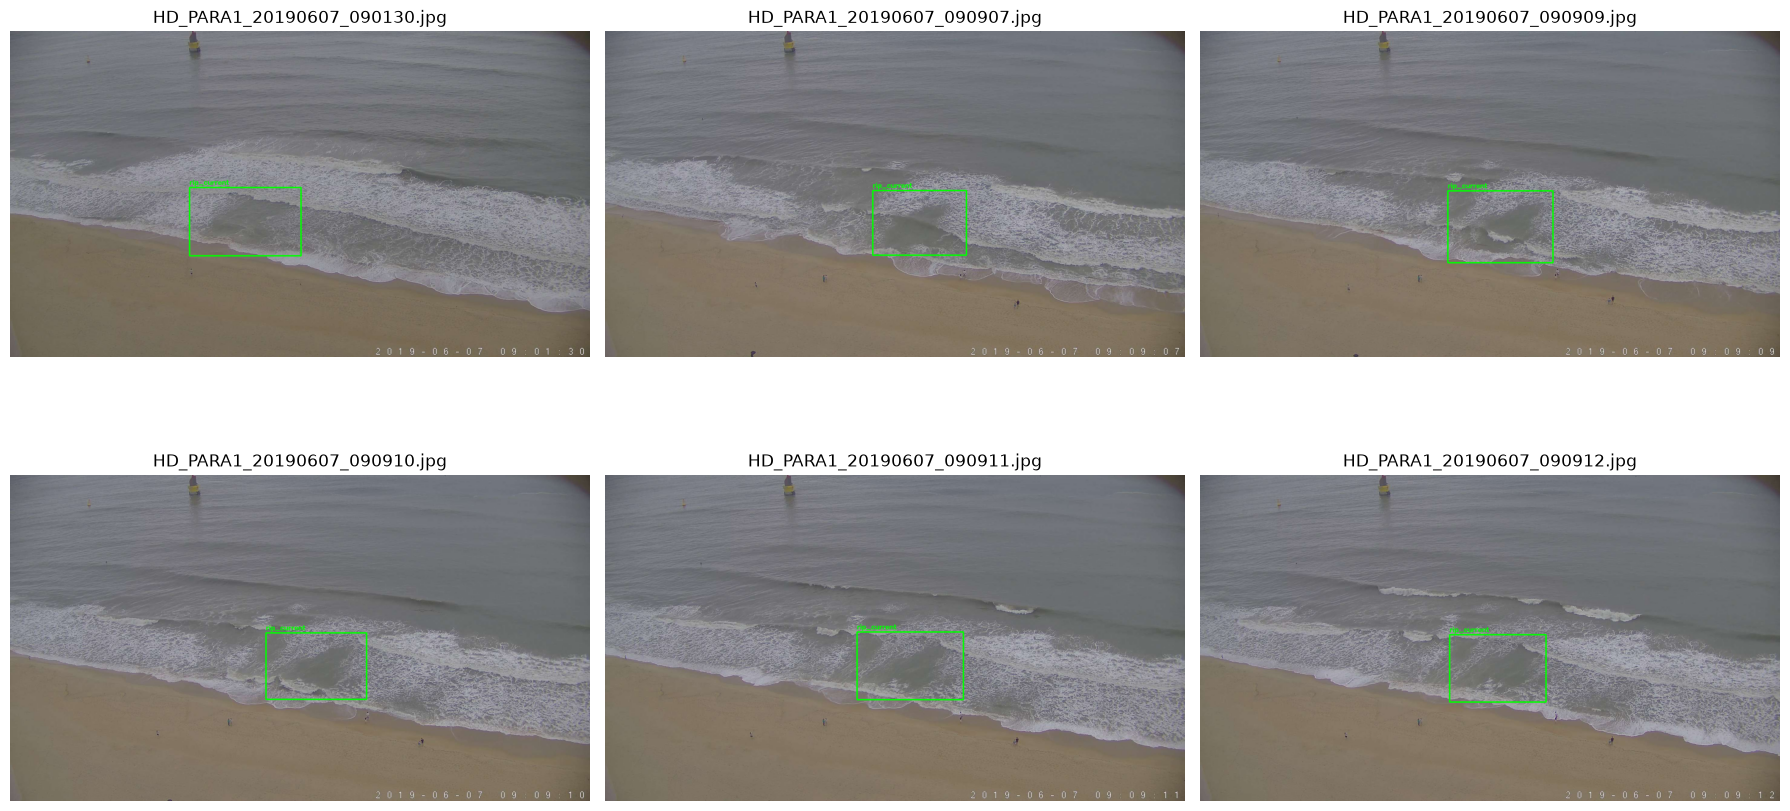

In [23]:
def draw_yolo_labels(image_path, label_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    h, w = image.shape[:2]

    if label_path.exists():
        lines = label_path.read_text(encoding="utf-8").strip().splitlines()

        for line in lines:
            if not line.strip():
                continue

            class_id, xc, yc, bw, bh = map(float, line.split())

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(
                image,
                CLASS_NAMES[int(class_id)],
                (x1, max(25, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


train_images = sorted((TRAIN_DIR / "images").glob("*"))

positive_train_images = [
    p for p in train_images
    if (TRAIN_DIR / "labels" / f"{p.stem}.txt").exists()
    and (TRAIN_DIR / "labels" / f"{p.stem}.txt").stat().st_size > 0
]

num_show = min(6, len(positive_train_images))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx in range(6):
    if idx >= num_show:
        axes[idx].axis("off")
        continue

    image_path = positive_train_images[idx]
    label_path = TRAIN_DIR / "labels" / f"{image_path.stem}.txt"

    axes[idx].imshow(draw_yolo_labels(image_path, label_path))
    axes[idx].set_title(image_path.name)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

# **5. YOLO 학습**

사전 학습된 YOLO11s를 사용하여 학습한다.
- epoch=50
- patience=10: 검증 성능이 10 epoch동안 개선되지 않으면 early stopping으로 종료된다.

In [21]:
model = YOLO(MODEL_NAME)

train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    project=str(PROJECT_DIR / "runs"),
    name="ripcurrent_yolo11s",
    exist_ok=True,
    seed=SEED,

    pretrained=True,
    plots=True,
    verbose=True,
)

FileNotFoundError: Image Not Found C:\MCP\agentlog\mcp04_multimodal\data\ripcurrent\train\images\HD_SEAC1_20190607_091714.jpg

# **6. 학습 수준 확인**

- Precision: 이안류라고 예측한 것 중 실제 이안류인 비율
- Recall: 실제 이안류 중 모델이 찾아낸 비율
- mAP50: IoU 0.5 기준 객체 탐지 성능
- mAP50-95: 더 엄격한 여러 IoU 기준을 평균한 성능
> 단일 숫자 하나만 보지 말고 Precision, Recall, mAP와 검증 이미지의 실제 박스 위치를 함께 확인해야 함

In [ ]:
import pandas as pd

In [ ]:
BEST_MODEL_PATH = (
    PROJECT_DIR
    / "runs"
    / "ripcurrent_yolo11s"
    / "weights"
    / "best.pt"
)

print("best.pt:", BEST_MODEL_PATH)
print("파일 존재:", BEST_MODEL_PATH.exists())

best_model = YOLO(str(BEST_MODEL_PATH))

metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True,
    verbose=False,
)

print("\n===== Validation 성능 =====")
print(f"Precision   : {metrics.box.mp:.4f}")
print(f"Recall      : {metrics.box.mr:.4f}")
print(f"mAP50       : {metrics.box.map50:.4f}")
print(f"mAP50-95    : {metrics.box.map:.4f}")

### Validation 결과에 대한 해석
- Precision: 0.3748
    - 모델이 이안류라고 예측한 결과 중 정답과 일치하는 비율이 충분히 높지 않다는 의미이다.
    - False Positive(오탐)가 많을 가능성이 있다.
        - 육지를 이안류라고 판단
        - 일반 파도를 이안류라고 판단
        - 밝은 영역을 이안류라고 판단
- Recall: 0.3000
    - 실제 이안류 정답 중 모델이 찾아낸 비율이 약 30% 수준이라는 의미이다.
    - Recall 낮으면 실제 이안류가 있는데도 박스를 만들지 못하는 False Negative(미탐)가 많다는 의미이다.
    - 안전과 관련된 시스템에서는 미탐이 특히 중요하다.
- mAP50: 0.3230
    - IoU 0.5를 기준으로 탐지 성능을 종합한 값이다.
    - 예측 박스와 정답 박스가 얼마나 겹치는지를 측정한다.
- mAP50-95: 0.0840
    - IoU 0.50부터 0.95까지 더 엄격한 여러 기준에서 계산한 mAP의 평균이다.
    - mAP50에 비해 mAP50-95가 크게 낮기 때문에, 단순히 이안류 주변을 대략적으로 찾는 것뿐 아니라 bounding box 위치와 크기를 정밀하게 맞추는 능력도 많이 부족한 상태로 해석할 수 있다.

### Underfitting과 Overfitting
1. Underfitting(과소적합)
    - 모델이 학습 데이터의 특징조차 충분히 배우지 못한 상태이다.
        - 학습시간 부족
        - 데이터 특징이 너무 복잡함
        - 모델 용량 부족
        - 입력 해상도가 너무 작아 필요한 특징이 손실됨
> epoch, 모델 크기, 이미지 크기 등을 검토해 볼 수 있다.

2. Overfitting(과적합)
    - Train 데이터에서는 좋아지지만 validation 데이터에서는 성능이 좋아지지 않거나 오히려 떨어지는 상태이다.
        - 데이터가 너무 적음
        - 비슷한 연속 프레임이 지나치게 많음
        - 특정 CCTV 배경을 모델이 외움
        - 학습을 지나치게 오래 수행함
> epoch를 더 늘리는 것은 오히려 문제를 악화시킬 수 있다.
> 데이터를 늘려야 한다.

### Loss curve 확인
result.csv에는 epoch 별 학습 결과가 저장된다.
    - train/box_loss
    - val/box_loss
    - train/cls_loss
    - val/cls_loss
    - Precision
    - Recall
    - mAP50
    - mAP50-95
> Validation mAP가 더 이상 개선되지 않으면 과적합을 의심해야 한다.

In [ ]:
# 학습 과정 CSV 확인
RESULTS_CSV = (
    PROJECT_DIR
    / "runs"
    / "ripcurrent_yolo11s"
    / "results.csv"
)

if RESULTS_CSV.exists():
    history = pd.read_csv(RESULTS_CSV)
    history.columns = history.columns.str.strip()

    display(history.tail(10))

    metric_cols = [
        c for c in history.columns
        if "metrics/" in c
    ]

    if metric_cols:
        history.plot(
            x="epoch",
            y=metric_cols,
            figsize=(12, 6),
            grid=True
        )
        plt.title("Validation Metrics by Epoch")
        plt.show()
else:
    print("results.csv를 찾을 수 없습니다.")

# **7. Test 데이터로 성능 확인**

In [ ]:
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    plots=True,
    verbose=False,
)

print("\n===== Test 성능 =====")
print(f"Precision   : {test_metrics.box.mp:.4f}")
print(f"Recall      : {test_metrics.box.mr:.4f}")
print(f"mAP50       : {test_metrics.box.map50:.4f}")
print(f"mAP50-95    : {test_metrics.box.map:.4f}")

In [ ]:
test_images = sorted([ # sorted(): 정렬된 리스트 반환 -> 매번 코드 실행 시 순서가 달라짐으로 인한 재현성 하락 방지
    p for p in (TEST_DIR / "images").iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS # 모든 확장자를 소문자로 변환
])

print("test_images 개수:", len(test_images))

CONFIDENCE = 0.25
num_show = min(3, len(test_images))

fig, axes = plt.subplots(num_show, 2, figsize=(18, 6 * num_show))

if num_show == 1:
    axes = np.array([axes])

for idx in range(num_show):
    image_path = test_images[idx]
    label_path = TEST_DIR / "labels" / f"{image_path.stem}.txt"

    # 정답
    gt_rgb = draw_yolo_labels(image_path, label_path)

    # 예측
    result = best_model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE,
        iou=0.7, # NMS(Non-Maximum Suppression) IoU threshold
        device=DEVICE,
        verbose=False,
    )[0]

    pred_bgr = result.plot()
    pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

    axes[idx, 0].imshow(gt_rgb)
    axes[idx, 0].set_title(f"Ground Truth - {image_path.name}")
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(pred_rgb)
    axes[idx, 1].set_title(
        f"Prediction - detections: {len(result.boxes)}"
    )
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 테스트 이미지별 confidence를 확인합니다.
for image_path in test_images[:10]:
    result = best_model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=0.01,   # 진단 목적으로만 낮게 설정
        iou=0.7,
        device=DEVICE,
        verbose=False,
    )[0]

    confidences = [
        round(float(box.conf.item()), 4)
        for box in result.boxes
    ]

    print(
        image_path.name,
        "| 탐지 수:",
        len(result.boxes),
        "| confidence:",
        confidences
    )

# **8. 학습 상태 판단 기준**

이안류 탐지에서 박스가 보인다고 좋은 모델이라고 판단하면 안된다.
- 정답 박스는 정상인데, 예측 박스가 계속 육지에 나타난다.
    > 모델이 잘못된 특징을 학습하고 있는 가능성이 높다.
- Recall이 매우 낮다.
    > 실제 이안류를 많이 놓치는 것이다.
- Precision이 매우 낮다.
    > 육지나 파도등을 이안류라고 잘못 판단하는 경우가 많다.
- train 성능만 좋아지고 validation 성능이 개선되지 않을 수 있다.
    > 과적합 가능성이 높다.
- mAP50은 높은데, mAP50-95가 매우 낮다.
    > 대략적 위치는 찾지만 박스 위치가 정확하지 않을 가능성이 높다.
> 먼저 위의 validation/test 지표와 정답/예측 비교 결과를 확인한 뒤, 모델 크기, augumentation, image, size 등을 추가로 조정한다.

# **9. 성능이 낮을때 해결책**

### **1. 라벨 정확성 확인**
- 박스가 실제 이안류 위치를 감싸는가?
- 박스가 지나치게 크거나 작지 않은가?
- 이미지 해상도와 JSON 좌표가 일치하는가?
- 객체가 없는 이미지에는 빈 라벨이 들어가는가?
> 라벨이 틀리면 어떤 모델을 사용해도 올바른 결과를 학습할 수 없다.

### **2. 데이터 양보다 먼저 다양성을 확인**
1. 더 많은 날짜
2. 더 다양한 시간대
3. 같은 해수욕장의 다른 CCTV 카메라
4. 다른 해수욕장
5. 서로 다른 파도 상태
6. 서로 다른 날씨와 조명
7. 다양한 크기와 위치의 이안류
8. 다양항 배경 이미지
> 비슷한 연속 프레임을 수천 장 추가하는 것보다 서로 다른 상황을 추가하는 것이 더 중요하다.

### **3. 연속 프레임의 중복 효과 줄이기**
연속 프레임이 지나치게 많으면 특정 장면이 데이터셋에서 과도한 비중을 차지한다. 전체 데이터를 구성할 때 필요에 따라 일정 시간으로 프레임을 샘플링하거나 영상 클립 단위로 데이터를 구성할 수 있다.

### **4. Hard Negative 수집**
모델이 자주 틀리는 배경을 Hard Negative라고 한다.
- 예시) 모델이 반복적으로 특정 파도, 해변 영역을 이안류라고 잘못 판단

그 장면을 객체가 없는 학습 데이터로 충분히 포함시키는 것이 도움이 될 수 있다. 모델 배포 후 발생하는 오탐을 다시 데이터로 수집하여 재학습과 과정을 반복하면 모델을 점진적으로 개선할 수 있다.

### **5. Epoch는 loss curve를 보고 결정**
데이터가 부족한 상태에서 epoch만 계속 늘리면 과적합 가능성이 커진다.
- Validation mAP가 계속 상승
    > 추가 학습을 검토한다.
- Validation mAP가 정체
    > epoch 증가 효과가 제한적이다.
- Train loss가 감소하고 validation 성능 약화 
    > 과적합 가능성이 높다.

### **6. 입력 해상도 검토**
현재 IMAGE_SIZE=640, 이안류 특징이 화면에서 작거나 세밀하다면 더 큰 입력 해상도가 도움이 될 수 있다.
- 해상도를 높이면
    - CPU 메모리 사용량 증가
    - 학습 시간 증가
    - batch 감소 가능

### **7. 데이터 문제를 확인 뒤 모델 크기 변경을 검토**
현재 모델은 YOLO11s, 더 큰 모델은 표현력이 증가할 수 있지만, 데이터가 부족하면 오히려 특정 데이터에 과적합할 수 있다.
- 권장 순서: 데이터/라벨 확인 > 데이터 다양성 확보 > 학습 곡선 확인 > 모델 크기 조정

### **8. Confidence를 낮추는 것은 해결책이 아님**
conf=0.01은 낮은 confidence 후보까지 확인하기 위한 진단용 설정이다. 실제 모델의 confidence가 0.03 ~ 0.10 수준인데, threshold만 0.01로 낯추면 탐지 박스는 늘어나지만 오탐도 크게 증가한다.

### **9. Detection이 문제 정의에 적합한 지도 검토해야 함**
현재 모델은 이안류 영역을 bounding box로 감싸는 object detection 방식이다. 이안류는 형태가 불규칙하고 경계가 명확하지 않은 영역이므로 실제 프로젝트 목적에 따라 segmentation이 더 적합할 수도 있다.